In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
df=pd.read_csv("bank_marketing_prediction.csv")

In [2]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
df.shape

(55000, 17)

In [4]:
df.nunique()

age            77
job            12
marital         3
education       4
default         2
balance      7974
housing         2
loan            2
contact         3
day            31
month          12
duration     1918
campaign       42
pdays         661
previous       43
poutcome        4
deposit         2
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        55000 non-null  int64
 1   job        55000 non-null  str  
 2   marital    55000 non-null  str  
 3   education  55000 non-null  str  
 4   default    55000 non-null  str  
 5   balance    55000 non-null  int64
 6   housing    55000 non-null  str  
 7   loan       55000 non-null  str  
 8   contact    55000 non-null  str  
 9   day        55000 non-null  int64
 10  month      55000 non-null  str  
 11  duration   55000 non-null  int64
 12  campaign   55000 non-null  int64
 13  pdays      55000 non-null  int64
 14  previous   55000 non-null  int64
 15  poutcome   55000 non-null  str  
 16  deposit    55000 non-null  str  
dtypes: int64(7), str(10)
memory usage: 7.1 MB


In [6]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

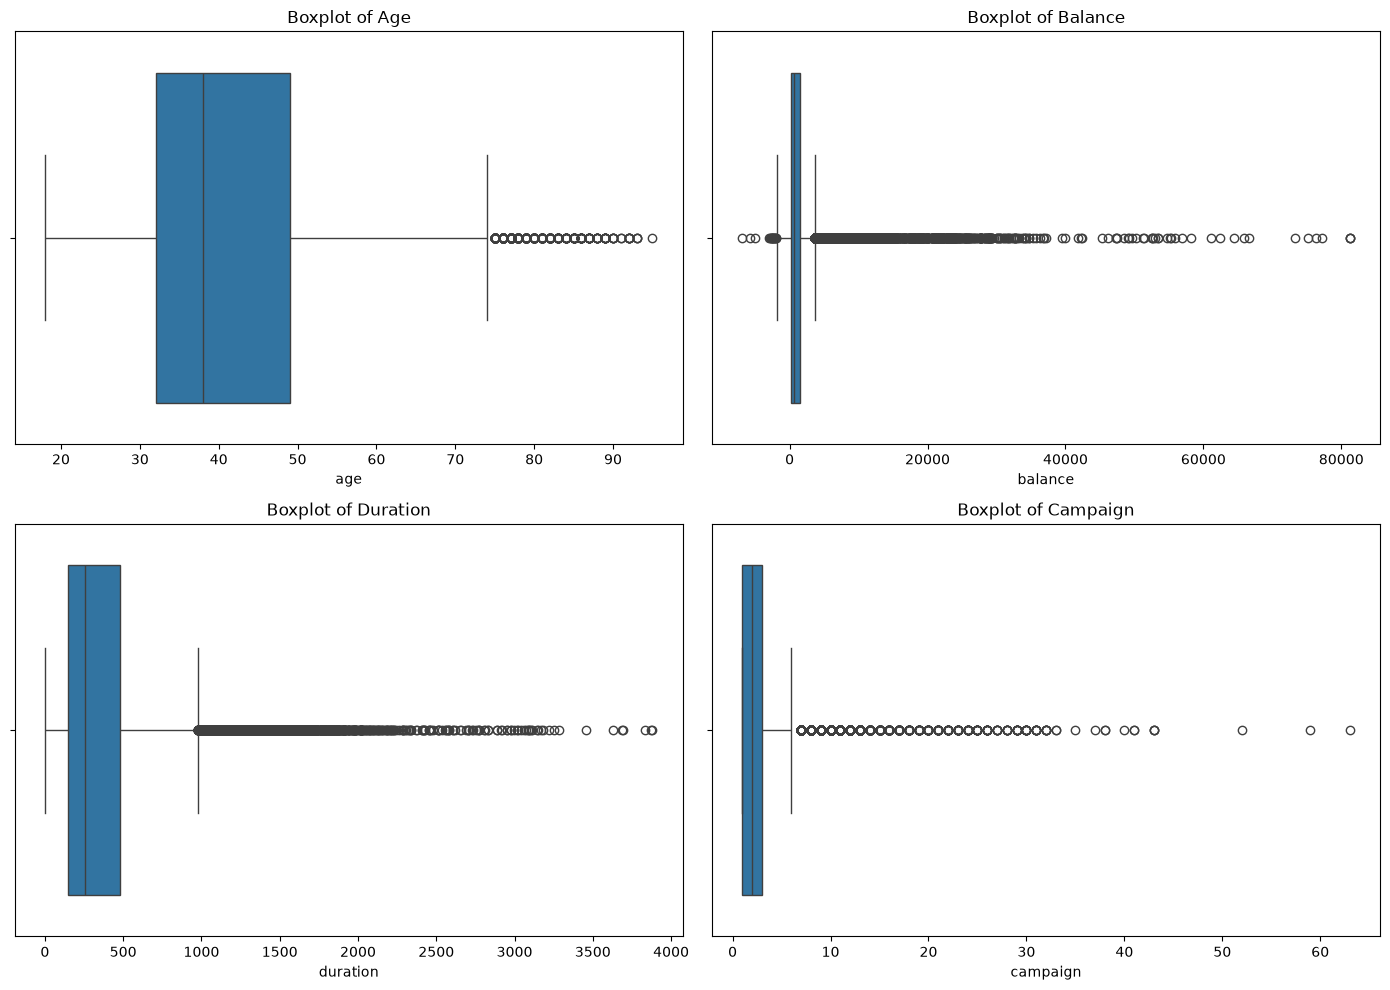

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 10))

# Subplot 1: Age
plt.subplot(2, 2, 1)
sns.boxplot(x="age", data=df)
plt.title("Boxplot of Age")

# Subplot 2: Balance
plt.subplot(2, 2, 2)
sns.boxplot(x="balance", data=df)
plt.title("Boxplot of Balance")

# Subplot 3: Duration
plt.subplot(2, 2, 3)
sns.boxplot(x="duration", data=df)
plt.title("Boxplot of Duration")

# Subplot 4: Campaign
plt.subplot(2, 2, 4)
sns.boxplot(x="campaign", data=df)
plt.title("Boxplot of Campaign")


plt.tight_layout()
plt.savefig('boxplots.png')

In [159]:
import pandas as pd
from scipy.stats import ttest_ind, chi2_contingency

# Load dataset (run BEFORE LabelEncoder)
df = pd.read_csv("bank_marketing_prediction.csv")

target = "deposit"
alpha = 0.05  # Significance threshold

# Separate numerical and categorical features
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [col for col in df.select_dtypes(include=["object", "string"]).columns if col != target]

selected_features = []
results = []

# 1. Two-Sample T-Test for Numerical Features
group_no = df[df[target] == "no"]
group_yes = df[df[target] == "yes"]

for col in num_cols:
    t_stat, p_val = ttest_ind(group_no[col], group_yes[col], equal_var=False)
    keep = p_val < alpha
    if keep:
        selected_features.append(col)
    results.append({
        "Feature": col,
        "Type": "Numerical",
        "Test": "T-Test",
        "Statistic": round(t_stat, 4),
        "p-value": p_val,
        "Decision": "Keep" if keep else "Drop"
    })

# 2. Chi-Square Test for Categorical Features
for col in cat_cols:
    contingency_table = pd.crosstab(df[col], df[target])
    chi2_stat, p_val, dof, _ = chi2_contingency(contingency_table)
    keep = p_val < alpha
    if keep:
        selected_features.append(col)
    results.append({
        "Feature": col,
        "Type": "Categorical",
        "Test": "Chi-Square",
        "Statistic": round(chi2_stat, 4),
        "p-value": p_val,
        "Decision": "Keep" if keep else "Drop"
    })

# Display summary table
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\nSelected Features for ANN:", selected_features)

# Filter DataFrame to keep only statistically significant features + target
df_selected = df[selected_features + [target]].copy()

  Feature        Type       Test  Statistic       p-value Decision
      age   Numerical     T-Test    -8.2434  1.715632e-16     Keep
  balance   Numerical     T-Test   -19.3320  5.664790e-83     Keep
      day   Numerical     T-Test    13.3908  7.944280e-41     Keep
 duration   Numerical     T-Test  -121.7716  0.000000e+00     Keep
 campaign   Numerical     T-Test    31.7910 1.605493e-219     Keep
    pdays   Numerical     T-Test   -35.3595 1.424918e-270     Keep
 previous   Numerical     T-Test   -34.9868 6.963095e-265     Keep
      job Categorical Chi-Square  2110.9083  0.000000e+00     Keep
  marital Categorical Chi-Square   603.8185 7.629201e-132     Keep
education Categorical Chi-Square   581.5224 1.020877e-125     Keep
  default Categorical Chi-Square    80.4099  3.042706e-19     Keep
  housing Categorical Chi-Square  2364.6871  0.000000e+00     Keep
     loan Categorical Chi-Square   638.4048 7.428061e-141     Keep
  contact Categorical Chi-Square  3806.4811  0.000000e+00     

In [8]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["job"]=label.fit_transform(df["job"])
df["marital"]=label.fit_transform(df["marital"])
df["education"]=label.fit_transform(df["education"])
df["default"]=label.fit_transform(df["default"])
df["housing"]=label.fit_transform(df["housing"])
df["loan"]=label.fit_transform(df["loan"])
df["contact"]=label.fit_transform(df["contact"])
df["month"]=label.fit_transform(df["month"])
df["poutcome"]=label.fit_transform(df["poutcome"])
df["deposit"]=label.fit_transform(df["deposit"])
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0,1,1,0,2343,1,0,2,5,8,1042,1,-1,0,3,1
1,56,0,1,1,0,45,0,0,2,5,8,1467,1,-1,0,3,1
2,41,9,1,1,0,1270,1,0,2,5,8,1389,1,-1,0,3,1
3,55,7,1,1,0,2476,1,0,2,5,8,579,1,-1,0,3,1
4,54,0,1,2,0,184,0,0,2,5,8,673,2,-1,0,3,1


In [45]:
df['deposit'].value_counts()

deposit
0    28939
1    26061
Name: count, dtype: int64

In [24]:
X = df.drop('deposit', axis=1)
y = df['deposit']

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
y_train_smote.value_counts()

deposit
1    23151
0    23151
Name: count, dtype: int64

In [27]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train_scaled = sc.fit_transform(X_train_smote)
x_test_scaled = sc.transform(X_test)

In [16]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [17]:
import tensorflow as tf

In [152]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Fix: Change output to 4 units (for 4 classes) with 'softmax' activation
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [153]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0,1,1,0,2343,1,0,2,5,8,1042,1,-1,0,3,1
1,56,0,1,1,0,45,0,0,2,5,8,1467,1,-1,0,3,1
2,41,9,1,1,0,1270,1,0,2,5,8,1389,1,-1,0,3,1
3,55,7,1,1,0,2476,1,0,2,5,8,579,1,-1,0,3,1
4,54,0,1,2,0,184,0,0,2,5,8,673,2,-1,0,3,1


In [154]:
# Compile the model first to avoid the ValueError
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train on the SCALED training features
history = model.fit(x_train_scaled, y_train_smote, epochs=30, validation_split=0.1)

Epoch 1/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8247 - loss: 0.3984 - val_accuracy: 0.8540 - val_loss: 0.3660
Epoch 2/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8418 - loss: 0.3619 - val_accuracy: 0.8575 - val_loss: 0.3609
Epoch 3/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8495 - loss: 0.3443 - val_accuracy: 0.8603 - val_loss: 0.3527
Epoch 4/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8582 - loss: 0.3284 - val_accuracy: 0.8624 - val_loss: 0.3458
Epoch 5/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8639 - loss: 0.3144 - val_accuracy: 0.8609 - val_loss: 0.3452
Epoch 6/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8695 - loss: 0.3017 - val_accuracy: 0.8614 - val_loss: 0.3461
Epoch 7/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8755 - loss: 0.2904 - val_accuracy: 0.8620 - val_loss: 0.3433
Epoch 8/30
1303/1303 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8814 - loss: 0.2800 - 

In [155]:
y_pred_probabilities = model.predict(x_test_scaled)
y_pred_sm = (y_pred_probabilities >= 0.5).astype(int)

344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [156]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred_sm))
print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

0.911
[[5298  490]
 [ 489 4723]]
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      5788
           1       0.91      0.91      0.91      5212

    accuracy                           0.91     11000
   macro avg       0.91      0.91      0.91     11000
weighted avg       0.91      0.91      0.91     11000



In [123]:
#CODE FOR REGULARIZATION
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2
            
model = Sequential([
    Dense(128, activation='relu',input_shape=(X_train.shape[1],),kernel_regularizer=l2(0.01)),

    Dense(64, activation='relu',kernel_regularizer=l2(0.01)),

    Dense(1, activation='sigmoid')
])

In [124]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

In [125]:
history=model.fit(x_train_scaled, y_train_smote, epochs=30,validation_split=0.3)

Epoch 1/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8161 - loss: 0.5852 - val_accuracy: 0.8315 - val_loss: 0.4357
Epoch 2/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8264 - loss: 0.4337 - val_accuracy: 0.8342 - val_loss: 0.4196
Epoch 3/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8283 - loss: 0.4238 - val_accuracy: 0.8346 - val_loss: 0.4131
Epoch 4/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8297 - loss: 0.4181 - val_accuracy: 0.8356 - val_loss: 0.4090
Epoch 5/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8309 - loss: 0.4140 - val_accuracy: 0.8366 - val_loss: 0.4054
Epoch 6/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8314 - loss: 0.4107 - val_accuracy: 0.8362 - val_loss: 0.4023
Epoch 7/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8320 - loss: 0.4081 - val_accuracy: 0.8371 - val_loss: 0.4000
Epoch 8/30
1013/1013 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8329 - loss: 0.4059 - 

In [126]:
y_pred_probabilities = model.predict(x_test_scaled)
y_pred_sm = (y_pred_probabilities >= 0.5).astype(int)

344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [127]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred_sm))
print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

0.8363636363636363
[[4764 1024]
 [ 776 4436]]
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      5788
           1       0.81      0.85      0.83      5212

    accuracy                           0.84     11000
   macro avg       0.84      0.84      0.84     11000
weighted avg       0.84      0.84      0.84     11000



In [136]:
#CODE FOR DROPOUT
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(128, activation='relu',input_shape=(X_train.shape[1],)),Dropout(0.1),

    Dense(64, activation='relu'),Dropout(0.1),

    Dense(1, activation='sigmoid')
])

In [137]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

In [138]:
history=model.fit(x_train_scaled, y_train_smote, epochs=30,validation_split=0.2)

Epoch 1/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8179 - loss: 0.4093 - val_accuracy: 0.8540 - val_loss: 0.3639
Epoch 2/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8365 - loss: 0.3754 - val_accuracy: 0.8563 - val_loss: 0.3514
Epoch 3/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8422 - loss: 0.3635 - val_accuracy: 0.8588 - val_loss: 0.3466
Epoch 4/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8464 - loss: 0.3531 - val_accuracy: 0.8585 - val_loss: 0.3420
Epoch 5/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8511 - loss: 0.3424 - val_accuracy: 0.8672 - val_loss: 0.3268
Epoch 6/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8557 - loss: 0.3346 - val_accuracy: 0.8671 - val_loss: 0.3252
Epoch 7/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8586 - loss: 0.3286 - val_accuracy: 0.8711 - val_loss: 0.3194
Epoch 8/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8616 - loss: 0.3232 - 

In [139]:
y_pred=model.predict(x_test_scaled)
#this will give values in rain or not 
y_pred_sm=(y_pred >= 0.5).astype(int)

344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [140]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred_sm))
print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

0.8982727272727272
[[5220  568]
 [ 551 4661]]
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      5788
           1       0.89      0.89      0.89      5212

    accuracy                           0.90     11000
   macro avg       0.90      0.90      0.90     11000
weighted avg       0.90      0.90      0.90     11000



In [142]:
#CODE FOR L2 + DROPOUT
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2

model = Sequential([
    Dense(128, activation='relu',
          input_shape=(X_train.shape[1],),
          kernel_regularizer=l2(0.01)),
          Dropout(0.1),

    Dense(64, activation='relu',
          kernel_regularizer=l2(0.01)),
          Dropout(0.1),

    Dense(1, activation='sigmoid')
])

In [143]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

In [144]:
history=model.fit(x_train_scaled, y_train_smote, epochs=30,validation_split=0.2)

Epoch 1/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8137 - loss: 0.5796 - val_accuracy: 0.8490 - val_loss: 0.4224
Epoch 2/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8231 - loss: 0.4387 - val_accuracy: 0.8523 - val_loss: 0.4076
Epoch 3/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8233 - loss: 0.4308 - val_accuracy: 0.8521 - val_loss: 0.4019
Epoch 4/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8263 - loss: 0.4251 - val_accuracy: 0.8524 - val_loss: 0.3988
Epoch 5/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8254 - loss: 0.4230 - val_accuracy: 0.8539 - val_loss: 0.3961
Epoch 6/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8269 - loss: 0.4202 - val_accuracy: 0.8537 - val_loss: 0.3938
Epoch 7/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8272 - loss: 0.4186 - val_accuracy: 0.8550 - val_loss: 0.3911
Epoch 8/30
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8284 - loss: 0.4171 - 

In [145]:
y_pred=model.predict(x_test_scaled)
#this will give values in rain or not 
y_pred_sm=(y_pred >= 0.5).astype(int)

344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [146]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred_sm))
print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

0.8374545454545455
[[4446 1342]
 [ 446 4766]]
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      5788
           1       0.78      0.91      0.84      5212

    accuracy                           0.84     11000
   macro avg       0.84      0.84      0.84     11000
weighted avg       0.85      0.84      0.84     11000



In [149]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True,verbose=1)

history = model.fit(x_train_scaled, y_train_smote,epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8350 - loss: 0.4026 - val_accuracy: 0.8583 - val_loss: 0.3783
Epoch 2/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8348 - loss: 0.4022 - val_accuracy: 0.8619 - val_loss: 0.3770
Epoch 3/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8366 - loss: 0.4013 - val_accuracy: 0.8597 - val_loss: 0.3756
Epoch 4/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8361 - loss: 0.3996 - val_accuracy: 0.8574 - val_loss: 0.3799
Epoch 5/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8360 - loss: 0.4001 - val_accuracy: 0.8600 - val_loss: 0.3776
Epoch 6/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8368 - loss: 0.4003 - val_accuracy: 0.8603 - val_loss: 0.3748
Epoch 7/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8375 - loss: 0.3977 - val_accuracy: 0.8582 - val_loss: 0.3771
Epoch 8/50
1158/1158 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8380 - loss: 0.3984 - 

In [150]:
y_pred=model.predict(x_test_scaled)
#this will give values in rain or not 
y_pred_sm=(y_pred >= 0.5).astype(int)

344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [151]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_test, y_pred_sm))
print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

0.8416363636363636
[[4503 1285]
 [ 457 4755]]
              precision    recall  f1-score   support

           0       0.91      0.78      0.84      5788
           1       0.79      0.91      0.85      5212

    accuracy                           0.84     11000
   macro avg       0.85      0.85      0.84     11000
weighted avg       0.85      0.84      0.84     11000

